# Cánticos del fútbol colombiano | Construcción de corpus
La primera fase integró **600 cánticos** de **17 de los 20 clubes** de la Liga BetPlay A de 2026.

## Datos y método
La unidad de análisis es un texto diferenciado que aparece transcrito en una fuente y tiene una asociación documentada con un club del universo de estudio. La fecha de corte es el 1 de septiembre de 2026. Los controles de cobertura se cotejaron con los conteos del corpus original. [Metodología de la entrega](https://drive.google.com/file/d/1NG-fPfCbhBrQ1z7qOv4yKR30NNLtK8L0/view).

In [1]:
from csv import DictReader
from pathlib import Path

def leer(archivo):
    with (Path('datos') / archivo).open(encoding='utf-8', newline='') as csv:
        return list(DictReader(csv))

def formato(n):
    return f'{n:,}'.replace(',', '.')

class Figura:
    def __init__(self, archivo):
        self.archivo = Path('figuras') / archivo

    def _repr_png_(self):
        return self.archivo.read_bytes()

## Calidad del corpus

In [2]:
calidad = {r['indicador']: int(r['conteo']) for r in leer('calidad_del_corpus.csv')}
cobertura = leer('cobertura_por_club.csv')
total = sum(int(fila['canticos_integrados']) for fila in cobertura)
assert calidad['capturas_crudas'] - calidad['duplicados_exactos_eliminados'] == total == 600
assert calidad['registros_finales'] == total
assert calidad['registros_revision_manual'] <= total
print('Capturas examinadas:', calidad['capturas_crudas'])
print('Duplicados exactos eliminados:', calidad['duplicados_exactos_eliminados'])
print('Casos marcados para revisión manual:', calidad['registros_revision_manual'])

Capturas examinadas: 610
Duplicados exactos eliminados: 10
Casos marcados para revisión manual: 88


## Cobertura por club

Clubes con registros recuperados: 17 de 20
Sin registros en este corte: Fortaleza CEIF, Llaneros FC, Águilas Doradas


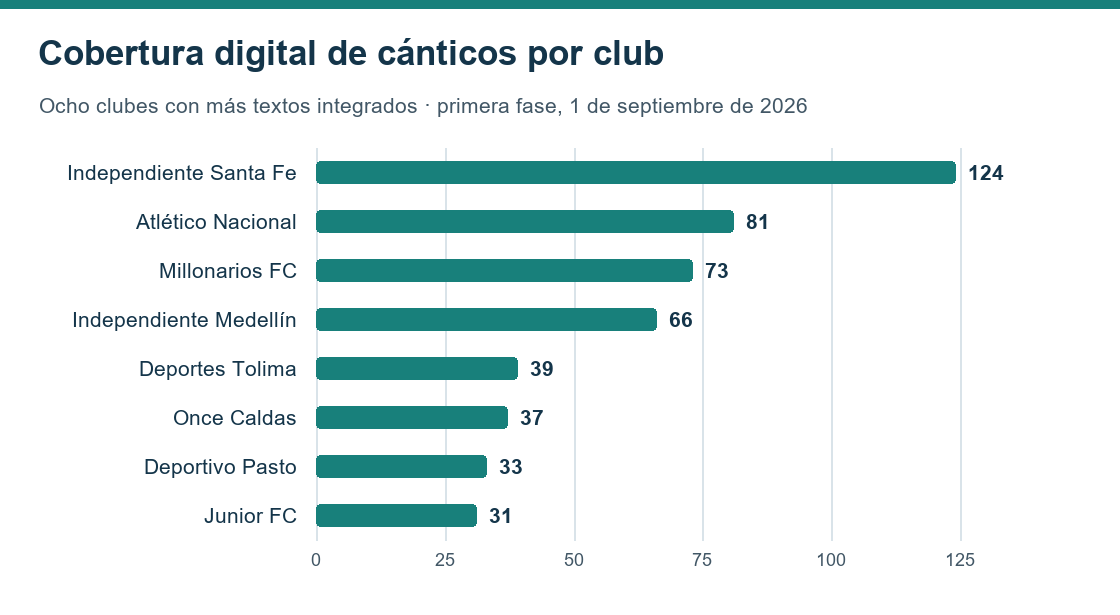

In [3]:
catalogo = {fila['club']: int(fila['canticos_integrados']) for fila in cobertura}
representados = sum(conteo > 0 for conteo in catalogo.values())
assert len(catalogo) == 20 and representados == calidad['clubes_con_canticos'] == 17
print(f'Clubes con registros recuperados: {representados} de {len(catalogo)}')
print('Sin registros en este corte:', ', '.join(club for club, n in catalogo.items() if n == 0))
display(Figura('cobertura.png'))

## Interpretación
Los conteos dependen de lo que estaba disponible en las fuentes. No representan el tamaño de cada hinchada ni informan por sí solos sobre temáticas o emociones. Esta versión de portafolio cubre la etapa de construcción del corpus y contiene únicamente tablas agregadas. `contar_cobertura.py` reproduce el recuento con copias locales autorizadas del catálogo y el corpus.